# Step 4: 2D Poisson PINN with warm start (near exact solution)

Same problem as `03_poisson_2d_pinn.ipynb` on $(0,1)^2$:

$$u(x,y)=\sin(\pi x)\sin(\pi y), \qquad -\Delta u = 2\pi^2\sin(\pi x)\sin(\pi y), \qquad u|_{\partial\Omega}=0.$$

**Idea:** Before PINN training, **pretrain** the network so that

$$u_\theta(x,y) \approx \alpha\, u_{\mathrm{exact}}(x,y), \qquad \alpha = 0.95 \text{ (default)}.$$

Then run the usual PDE + boundary loss. This mimics having a **good initial guess** (e.g. from a coarse solver or asymptotics).

We compare **random init** vs **warm start** on the same budget.

In [1]:
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

PI = np.pi
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)

set_seed(42)
print("device:", device)


device: cpu


In [2]:
def exact_u(x, y):
    if isinstance(x, torch.Tensor):
        return torch.sin(PI * x) * torch.sin(PI * y)
    return np.sin(PI * x) * np.sin(PI * y)


def source_xy(x, y):
    return (2.0 * PI**2) * torch.sin(PI * x) * torch.sin(PI * y)


class MLP2d(nn.Module):
    def __init__(self, width=64, depth=5):
        super().__init__()
        layers = [nn.Linear(2, width), nn.Tanh()]
        for _ in range(depth - 1):
            layers += [nn.Linear(width, width), nn.Tanh()]
        layers.append(nn.Linear(width, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x, y):
        return self.net(torch.stack([x, y], dim=-1)).squeeze(-1)


def grad(y, x):
    return torch.autograd.grad(
        y, x, grad_outputs=torch.ones_like(y), create_graph=True, retain_graph=True
    )[0]


def sample_interior(n, eps=1e-3):
    x = eps + (1.0 - 2 * eps) * torch.rand(n, device=device)
    y = eps + (1.0 - 2 * eps) * torch.rand(n, device=device)
    return x, y


def sample_boundary(n_edge, eps=1e-3):
    t = eps + (1.0 - 2 * eps) * torch.rand(n_edge, device=device)
    z = torch.zeros(n_edge, device=device)
    o = torch.ones(n_edge, device=device)
    x = torch.cat([t, t, z, o])
    y = torch.cat([z, o, t, t])
    return x, y


def rel_l2_grid(model, n=80):
    xp = np.linspace(0, 1, n)
    yp = np.linspace(0, 1, n)
    Xg, Yg = np.meshgrid(xp, yp, indexing="ij")
    Ue = exact_u(Xg, Yg)
    xt = torch.tensor(Xg.ravel(), dtype=torch.float32, device=device)
    yt = torch.tensor(Yg.ravel(), dtype=torch.float32, device=device)
    with torch.no_grad():
        Up = model(xt, yt).cpu().numpy().reshape(Xg.shape)
    return np.linalg.norm(Up - Ue) / (np.linalg.norm(Ue) + 1e-12), Xg, Yg, Ue, Up


## Phase A: Pretrain to $u \approx \alpha\, u_{\mathrm{exact}}$

Only **supervised** loss (no PDE residual). Sample in the **closed square** $[0,1]^2$ including boundary — target is $\alpha\sin(\pi x)\sin(\pi y)$, which is **not** exactly zero on the boundary when $\alpha \neq 1$. That is intentional: we warm-start the **bulk shape**, then PINN corrects boundary and PDE.

In [3]:
def pretrain_ansatz(
    model,
    alpha=0.95,
    epochs=3000,
    lr=1e-3,
    n_bulk=4096,
    n_edge=256,
    verbose=True,
):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for epoch in range(epochs):
        opt.zero_grad()
        xb, yb = sample_interior(n_bulk)
        xe, ye = sample_boundary(n_edge)
        xt = torch.cat([xb, xe])
        yt = torch.cat([yb, ye])
        pred = model(xt, yt)
        target = alpha * exact_u(xt, yt)
        loss = torch.mean((pred - target) ** 2)
        loss.backward()
        opt.step()
        hist.append(loss.item())
        if verbose and (epoch + 1) % 1000 == 0:
            err, _, _, _, _ = rel_l2_grid(model)
            print(f"pretrain {epoch+1:5d}  mse={loss.item():.3e}  rel_L2(vs exact)={err:.4e}")
    return hist


## Phase B: PINN finetuning (PDE + boundary)

In [4]:
def train_pinn(
    model,
    epochs=10000,
    lr=1e-3,
    w_bc=100.0,
    n_int=2048,
    n_edge=128,
    verbose=True,
):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for epoch in range(epochs):
        opt.zero_grad()
        xi, yi = sample_interior(n_int)
        xi = xi.clone().requires_grad_(True)
        yi = yi.clone().requires_grad_(True)
        ui = model(xi, yi)
        res = -grad(grad(ui, xi), xi) - grad(grad(ui, yi), yi) - source_xy(xi, yi)
        loss_pde = torch.mean(res**2)

        xb, yb = sample_boundary(n_edge)
        loss_bc = torch.mean(model(xb, yb) ** 2)

        loss = loss_pde + w_bc * loss_bc
        loss.backward()
        opt.step()
        hist.append(loss.item())
        if verbose and (epoch + 1) % 2000 == 0:
            err, _, _, _, _ = rel_l2_grid(model)
            print(
                f"pinn {epoch+1:5d}  loss={loss.item():.3e}  pde={loss_pde.item():.3e}  "
                f"bc={loss_bc.item():.3e}  rel_L2={err:.4e}"
            )
    return hist


## Experiment: random init vs warm start ($\alpha=0.95$)

Same network size and same PINN epoch budget after pretrain.

In [5]:
ALPHA = 0.95
PRE_EPOCHS = 3000
PINN_EPOCHS = 10000
WIDTH, DEPTH = 64, 5

# --- cold start ---
set_seed(42)
model_cold = MLP2d(WIDTH, DEPTH).to(device)
hist_pinn_cold = train_pinn(model_cold, epochs=PINN_EPOCHS)
err_cold, Xg, Yg, Ue, Up_cold = rel_l2_grid(model_cold)
print("=== cold start (random init) ===")
print("final rel_L2:", err_cold)

# --- warm start ---
set_seed(42)
model_warm = MLP2d(WIDTH, DEPTH).to(device)
hist_pre = pretrain_ansatz(model_warm, alpha=ALPHA, epochs=PRE_EPOCHS)
err_after_pre, _, _, _, Up_pre = rel_l2_grid(model_warm)
print("=== after pretrain only ===")
print(f"target was {ALPHA} * exact; rel_L2 vs exact:", err_after_pre)

hist_pinn_warm = train_pinn(model_warm, epochs=PINN_EPOCHS)
err_warm, _, _, _, Up_warm = rel_l2_grid(model_warm)
print("=== warm start (pretrain + PINN) ===")
print("final rel_L2:", err_warm)


pinn  2000  loss=8.294e-03  pde=6.572e-03  bc=1.722e-05  rel_L2=6.2264e-03
pinn  4000  loss=1.468e-02  pde=3.280e-03  bc=1.140e-04  rel_L2=1.3025e-02
pinn  6000  loss=2.719e-03  pde=1.305e-03  bc=1.415e-05  rel_L2=7.6278e-03
pinn  8000  loss=2.403e-03  pde=8.302e-04  bc=1.572e-05  rel_L2=6.2362e-03
pinn 10000  loss=1.261e-02  pde=1.667e-03  bc=1.094e-04  rel_L2=2.3568e-02
=== cold start (random init) ===
final rel_L2: 0.02356771751557811
pretrain  1000  mse=7.122e-05  rel_L2(vs exact)=5.0244e-02
pretrain  2000  mse=2.295e-04  rel_L2(vs exact)=3.6380e-02
pretrain  3000  mse=1.848e-04  rel_L2(vs exact)=3.3728e-02
=== after pretrain only ===
target was 0.95 * exact; rel_L2 vs exact: 0.03372797501455182
pinn  2000  loss=8.063e-03  pde=4.273e-03  bc=3.790e-05  rel_L2=1.0633e-02
pinn  4000  loss=4.471e-03  pde=1.543e-03  bc=2.928e-05  rel_L2=1.4161e-02
pinn  6000  loss=1.715e-03  pde=1.195e-03  bc=5.199e-06  rel_L2=7.8268e-03
pinn  8000  loss=1.385e-03  pde=9.149e-04  bc=4.704e-06  rel_L2=3.

## Plots

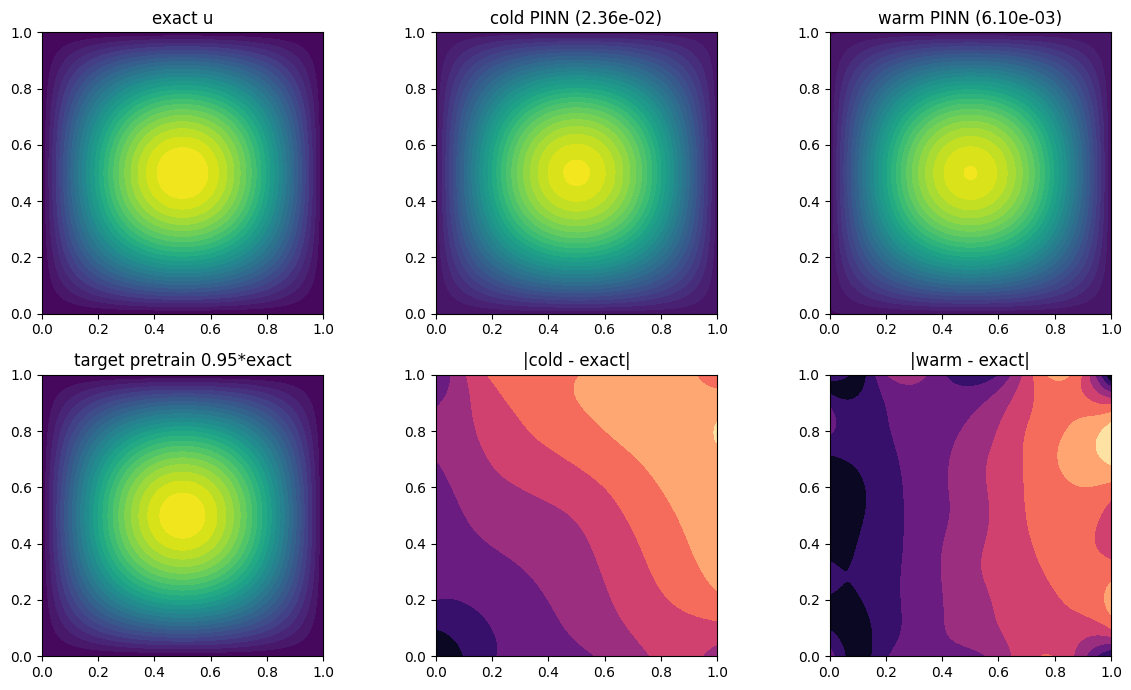

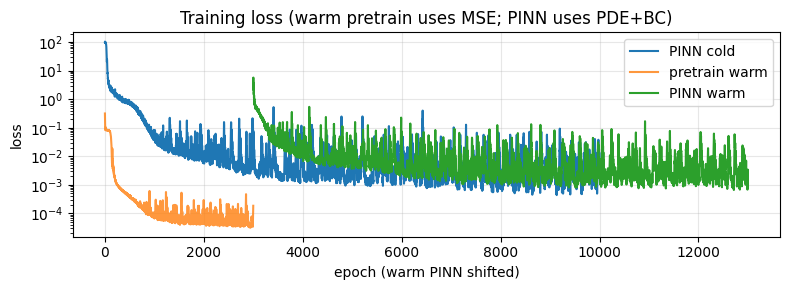

Improvement factor cold/warm: 3.86x


In [6]:
fig, ax = plt.subplots(2, 3, figsize=(12, 7))
kw = dict(levels=30, cmap="viridis")
ax[0, 0].contourf(Xg, Yg, Ue, **kw); ax[0, 0].set_title("exact u")
ax[0, 1].contourf(Xg, Yg, Up_cold, **kw); ax[0, 1].set_title(f"cold PINN ({err_cold:.2e})")
ax[0, 2].contourf(Xg, Yg, Up_warm, **kw); ax[0, 2].set_title(f"warm PINN ({err_warm:.2e})")
ax[1, 0].contourf(Xg, Yg, ALPHA * Ue, **kw); ax[1, 0].set_title(f"target pretrain {ALPHA}*exact")
ax[1, 1].contourf(Xg, Yg, np.abs(Up_cold - Ue), cmap="magma"); ax[1, 1].set_title("|cold - exact|")
ax[1, 2].contourf(Xg, Yg, np.abs(Up_warm - Ue), cmap="magma"); ax[1, 2].set_title("|warm - exact|")
for a in ax.ravel():
    a.set_aspect("equal")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3))
plt.semilogy(hist_pinn_cold, label="PINN cold")
plt.semilogy(hist_pre, label="pretrain warm", alpha=0.8)
plt.semilogy(np.arange(PRE_EPOCHS, PRE_EPOCHS + PINN_EPOCHS), hist_pinn_warm, label="PINN warm")
plt.xlabel("epoch (warm PINN shifted)"); plt.ylabel("loss"); plt.legend(); plt.grid(True, alpha=0.3)
plt.title("Training loss (warm pretrain uses MSE; PINN uses PDE+BC)")
plt.tight_layout()
plt.show()

print(f"Improvement factor cold/warm: {err_cold / err_warm:.2f}x")


## Notes

- **$\alpha=0.95$** is only an example; set `ALPHA = 1.0` to pretrain on the exact formula (still not identical to PINN solution until BC+PDE are enforced).
- You can pretrain on **any** grid data: `target = torch.tensor(u_fd.ravel())` from a coarse FD solve.
- If pretrain dominates wrongly, **lower `PRE_EPOCHS`** or use a **smaller LR** in Phase B.
- **Strict boundary:** for $\alpha<1$, pretrain target is nonzero on edges; PINN BC term pulls back to $u=0$.